In [1]:
from helpers import *

In [2]:
cmap_S = 'PuOr_r'
def get_state(snapshot_pattern, target_time):
    import h5py
    import numpy as np
    import glob

    files = sorted(glob.glob(snapshot_pattern))
    if not files:
        raise FileNotFoundError(f"No files match pattern: {snapshot_pattern}")

    time_list = []
    s_list = []

    x = z = None

    # --- loop over files ---
    for i, fname in enumerate(files):
        with h5py.File(fname, 'r') as f:
            # get coords only once
            if i == 0:
                x_key = next(k for k in f['scales'] if k.startswith('x_hash'))
                z_key = next(k for k in f['scales'] if k.startswith('z_hash'))

                x = np.squeeze(f[f'scales/{x_key}'][:])
                z = np.squeeze(f[f'scales/{z_key}'][:])

            # collect data
            time_list.append(f['scales/sim_time'][:])
            s_list.append(f['tasks']['s'][:])

    # --- concatenate across files ---
    time = np.concatenate(time_list)
    s = np.concatenate(s_list)

    # --- find closest time ---
    idx = np.argmin(np.abs(time - target_time))

    sa = s[idx]

    # optional debug
    print(f"Requested time: {target_time}, selected: {time[idx]}")

    return x, z, sa
def get_ECS(path):
    [x,z_,sa,_,_]=return_fields(path)
    return x,z,sa

def plot_state(x,z,sa,name=None,symmetric=False):
    fig, ax = plt.subplots(figsize = (3,3))
    X, Z = np.meshgrid(x, z) 
    smin = np.min(sa)
    smax = np.max(sa)
    absmax = max(abs(smin),abs(smax))
    ax.pcolormesh(X, Z, sa.T, vmin=-absmax if symmetric else smin, vmax=smax, cmap = cmap_S)
    plt.yticks([])
    plt.xticks([])
    ax.set_aspect('equal')
    plt.tight_layout()
    if name is not None:
        plt.savefig(name, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
def shift_field(sa, ax, az):
    Nz = sa.shape[0]
    Nx = sa.shape[1]
    shift_x = int(round(ax * Nx))
    shift_z = int(round(az * Nz))
    shift_sa = np.roll(sa, shift=(shift_x, shift_z), axis=(0, 1))
    return shift_sa

Requested time: 40.2, selected: 40.20010124167185


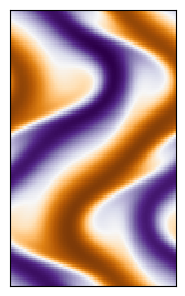

In [ ]:
[x,z,sa] = get_state(snapshot_pattern='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS_old/snapshots/snapshots_s*.h5',target_time=40.2)
sa = shift_field(sa, 0.35, 0.2)
plot_state(x,z,sa,name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS_old/snapshot_WF.png')
# [x,z,sa] = get_ECS(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_WF/solution.h5')
# plot_state(x,z,sa,name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_WF/WF.png')

Requested time: 49.5, selected: 49.500169428874194


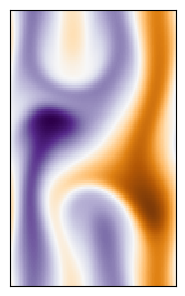

In [ ]:
[x,z,sa] = get_state(snapshot_pattern='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS_old/snapshots/snapshots_s*.h5',target_time=49.5)
sa = shift_field(sa, 0.17, 0.35)
plot_state(x,z,sa,name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS_old/snapshot_H.png')
# [x,z,sa] = get_ECS(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_H/solution.h5')
# plot_state(x,z,sa,name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_H/H.png')

Requested time: 25.3, selected: 25.299399419221963


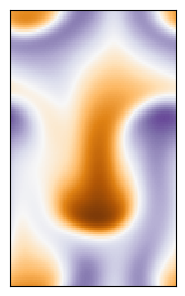

In [ ]:
[x,z,sa] = get_state(snapshot_pattern='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS_old/snapshots/snapshots_s*.h5',target_time=25.3)
sa = shift_field(sa, 0.17, -0.25)
plot_state(x,z,sa,name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS_old/snapshot_TM1.png',symmetric=True)
# [x,z,sa] = get_ECS(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TM1/solution.h5')
# plot_state(x,z,sa,name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TM1/TM1.png')

Requested time: 64.2, selected: 64.20003535743922


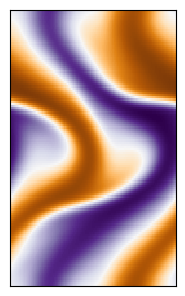

In [6]:
[x,z,sa] = get_state(snapshot_pattern='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS_old/snapshots/snapshots_s*.h5',target_time=64.2)
sa = shift_field(sa, -0.3, 0.0)
plot_state(x,z,sa,name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS_old/snapshot_TWF.png')
# [x,z,sa] = get_ECS(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TWF/solution.h5')
# plot_state(x,z,sa,name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TWF/TWF.png')